# Advection scheme

The fluid's enthalpy is advected along the flow path by upwinding. PyBaMM's upwinding takes
the value on each cell face from the cell upstream of it: first order, so it smears a
temperature front as it moves along the flow path, and the error only halves when the mesh
is doubled.

PyTES models use a second-order scheme by default (MUSCL, with the van Albada limiter), on
uniform or non-uniform meshes. It only changes the values on the cell faces, so the model,
its variables and its exact energy balance are the same with either. The first-order scheme
is selected as any PyBaMM spatial method:

```python
spatial_methods = {
    **model.default_spatial_methods,
    "flow path": pytes.compat.fluid_spatial_method("first order"),
}
pybamm.Simulation(model, spatial_methods=spatial_methods)
```

The second-order scheme lives in `pytes.compat` until PyBaMM's finite volumes offer it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pybamm

import pytes
from pytes import validation
from pytes.compat import fluid_spatial_method
from pytes.materials import SensibleMaterial
from pytes.submodels import DeviceEnergy, EnthalpyStorage, WallCoupling


def with_scheme(model, scheme):
    """The model's spatial methods, with the given scheme on the flow path"""
    return {**model.default_spatial_methods, "flow path": fluid_spatial_method(scheme)}

## Against Schumann's solution

The sensible packed bed of the validation notebook: capsules conductive enough to be lumped,
charged with fluid at 70 °C from 32 °C, against Schumann's analytical solution.

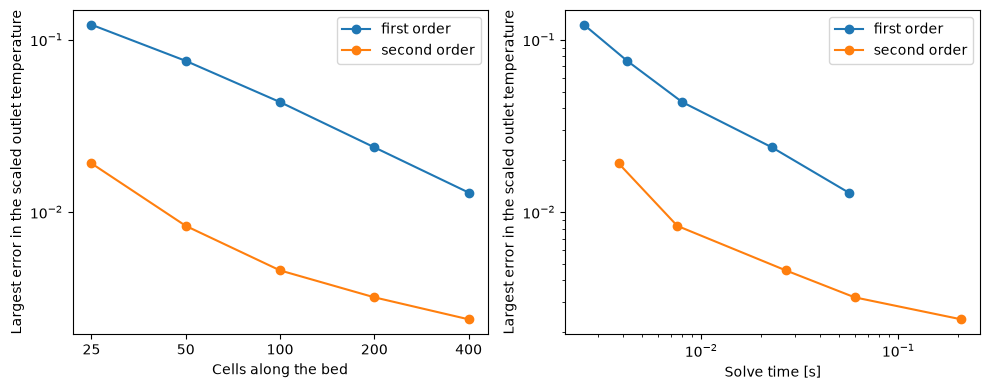

In [2]:
base = pytes.PackedBedModel()
param = base.param
geometry = base.submodels["storage"].storage_geometry
fluid = base.submodels["fluid"]
storage = EnthalpyStorage(param, SensibleMaterial("Capsule"), geometry, label="Capsule")
sensible = pytes.ComposedModel(
    {
        "fluid": fluid,
        "storage": storage,
        "coupling": WallCoupling(param, param.fluid, "Capsule", geometry),
        "device energy": DeviceEnergy(param, fluid, [storage]),
    },
    param,
    name="Sensible packed bed",
    defaults_from=base,
)
pv = base.default_parameter_values
pv.update(
    {
        "Capsule conductivity [W.m-1.K-1]": 1e3,
        "Capsule density [kg.m-3]": 1000,
        "Capsule specific heat capacity [J.kg-1.K-1]": 2000,
        "Heat transfer coefficient [W.m-2.K-1]": 300,
    },
    check_already_exists=False,
)
h, R, eps = 300, pv["Capsule radius [m]"], pv["Bed porosity"]
Z, A = pv["Bed length [m]"], pv["Bed cross-sectional area [m2]"]
rho_f = pv["Heat transfer fluid density [kg.m-3]"]
c_f = pv["Heat transfer fluid specific heat capacity [J.kg-1.K-1]"]
a = 3 * (1 - eps) / R
u = pv["Mass flow rate [kg.s-1]"] / (rho_f * eps * A)
xi = h * a * Z / (eps * rho_f * c_f * u)
rate = h * a / ((1 - eps) * 1000 * 2000)
t = np.linspace(0, 3000, 151)
exact = np.array([validation.schumann(xi, rate * (ti - Z / u))[0] for ti in t])

cells = [25, 50, 100, 200, 400]
fig, (ax_cells, ax_time) = plt.subplots(1, 2, figsize=(10, 4))
for scheme in ("first order", "second order"):
    errors, times = [], []
    for n_z in cells:
        solution = pybamm.Simulation(
            sensible,
            parameter_values=pv,
            var_pts={base.r: 5, base.z: n_z},
            spatial_methods=with_scheme(sensible, scheme),
        ).solve([0, t[-1]], t_interp=t)
        theta = (solution["Outlet temperature [K]"].entries - 305.15) / 38
        errors.append(np.max(np.abs(theta - exact)))
        times.append(solution.solve_time.value)
    ax_cells.loglog(cells, errors, "o-", label=scheme)
    ax_time.loglog(times, errors, "o-", label=scheme)
ax_cells.set_xticks(cells, [str(n) for n in cells])
ax_cells.minorticks_off()
ax_cells.set_xlabel("Cells along the bed")
ax_time.set_xlabel("Solve time [s]")
for ax in (ax_cells, ax_time):
    ax.set_ylabel("Largest error in the scaled outlet temperature")
    ax.legend()
plt.tight_layout()
plt.show()

The second-order scheme on 25 cells is more accurate than first order on 400. Its error
levels off near 0.3 %: what is left is the difference between the model (a capsule
conducting heat) and Schumann's (a lumped capsule), not the scheme. At equal accuracy it is
far cheaper, though per cell it costs up to a few times more.

## A sharp front: the finned tube

The default finned-tube discharge, on 20 cells along the tube, against the second-order scheme
on 80 cells.

second order, 80 cells: solve time 3.769 s


first order, 20 cells: solve time 429.006 ms
  largest difference from the reference: 0.820 K


second order, 20 cells: solve time 489.040 ms
  largest difference from the reference: 0.163 K


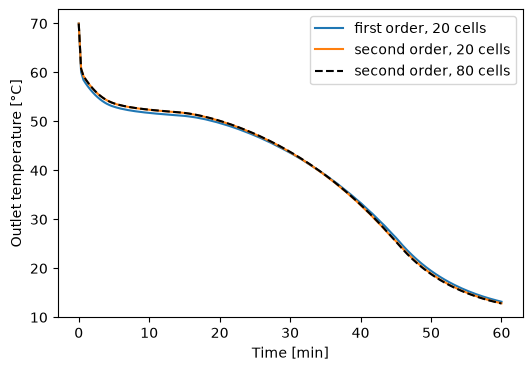

In [3]:
model = pytes.SharpFrontModel()
t = np.linspace(0, 3600, 181)


def outlet(scheme, n_z):
    var_pts = {**model.default_var_pts, model.z: n_z}
    solution = pybamm.Simulation(
        model, var_pts=var_pts, spatial_methods=with_scheme(model, scheme)
    ).solve([0, t[-1]], t_interp=t)
    print(f"{scheme}, {n_z} cells: solve time {solution.solve_time}")
    return solution["Outlet temperature [degC]"].entries


reference = outlet("second order", 80)
fig, ax = plt.subplots(figsize=(6, 4))
for scheme in ("first order", "second order"):
    T = outlet(scheme, 20)
    print(
        f"  largest difference from the reference: {np.max(np.abs(T - reference)):.3f} K"
    )
    ax.plot(t / 60, T, label=f"{scheme}, 20 cells")
ax.plot(t / 60, reference, "k--", label="second order, 80 cells")
ax.set_xlabel("Time [min]")
ax.set_ylabel("Outlet temperature [°C]")
ax.legend()
plt.show()

Energy is conserved exactly with either scheme, on uniform or stretched meshes, and the
limited scheme creates no new extrema: the fluid stays between its inlet and initial
temperatures. The measurements behind choosing it as the default, including the packed bed,
are in the findings (F-052).